### Case Study: **Carlingford Igneous Centre, Ireland**

*Basic to Evolved - Subalkaline Tholeiitic*

[![Documentation](https://img.shields.io/badge/docs-latest-blue?logo=read-the-docs&logoColor=white)](https://hades-obol.readthedocs.io/en/latest/)
[![GitHub](https://img.shields.io/badge/GitHub-Hades-red?logo=github)](https://github.com/Jack6228/Hades)
[![PyPI](https://img.shields.io/pypi/v/hades-obol?logo=pypi&logoColor=white)](https://pypi.org/project/hades-obol/)
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Jack6228/Hades/blob/main/examples/ireland/carlingford.ipynb)

The Carlingford Igneous Centre, northeastern Ireland is an example of bimodal intrusions that form part of the North Atlantic Igneous province. Although the rhyolites in this complex are thought to be formed through simple fractional crystallisation of basaltic parental magmas, the andesite and dacitic rocks show evidence of contamination by metasiltstones. Hades models the mafic to intermediate AFC trends in its cone sheet complex.

> Note: This notebook is not intended to act as a tutorial directly, but to demonstrate this case study. See the [Hades Python Tutorial ↗](https://hades-obol.readthedocs.io/en/latest/api/tutorial.html) for more detailed explanations.

**Key links**: [GitHub Folder ↗](https://github.com/Jack6228/Hades/tree/main/examples/ireland) | [Documentation Page ↗](https://hades-obol.readthedocs.io/en/latest/case_studies/ireland/index.html) | [API Reference ↗](https://hades-obol.readthedocs.io/en/latest/api/index.html)

---

**Model Setup**

In [1]:
# Import the Obol class from the hades module and initialise a new model
from hades import Obol
model = Obol.newModel()

# Load the data suite
model.load_data_suite('./Carlingford.xlsx')

# Select samples to form the projected LLOD
model.select_initial_composition([None, None, 'CS4E', 'B4', '288-8a', 'LWG2'])

hades-obol v0.8.4. This is a pre-release version. Check for updates using hades.check_for_updates()


Primary       : n/a
Primitive     : n/a
Basic         : 'CS4E'
Intermediate  : 'B4'
Evolved       : '288-8a'
End           : 'LWG2'
4/6 phases have been set with user-provided initial compositions.


**Customisation**

Here, we can configure KD values, contributing minerals and their compositions

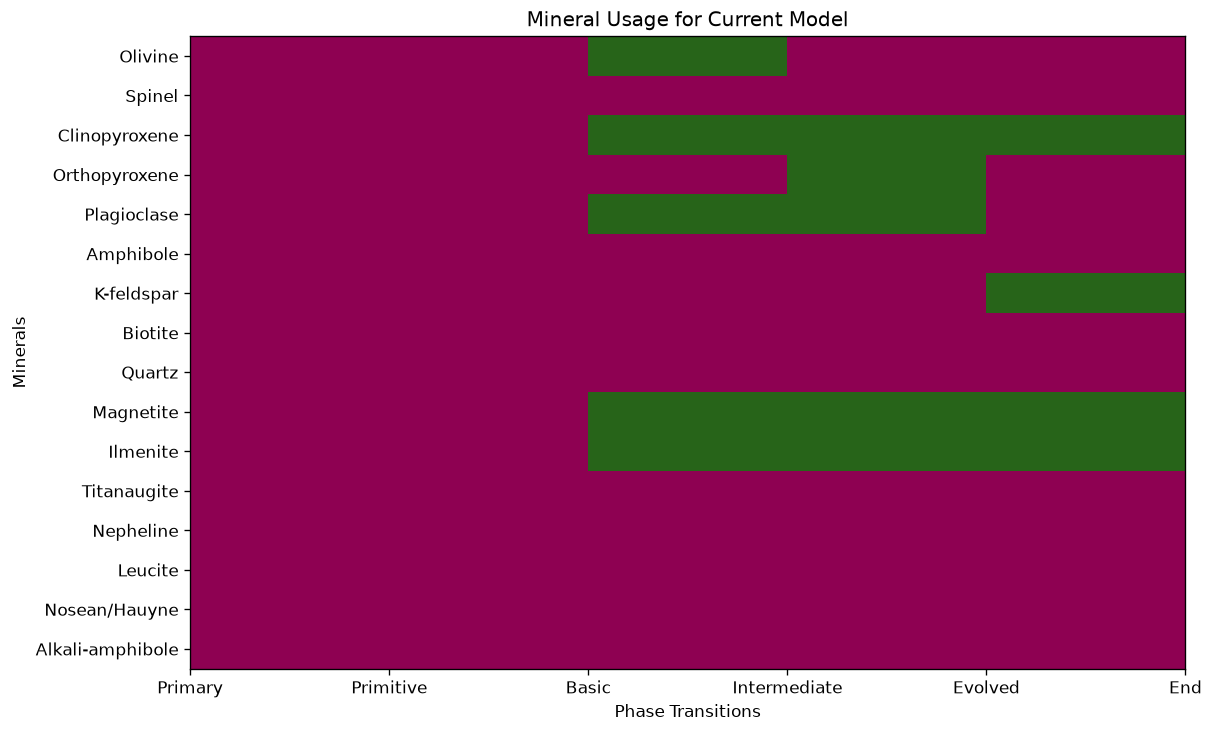

In [2]:
# Define which minerals contribute to the assemblage and in which phases
model.set_mineral_usage(
    __=False,               # Sets all minerals to False 
    basic__olivine=True,
    basic__plagioclase=True,
    basic__cpx=True,
    basic__magnetite=True,
    basic__ilmenite=True,
    intermediate__olivine=False,
    intermediate__plagioclase=True,
    intermediate__opx=True,
    intermediate__cpx=True,
    intermediate__magnetite=True,
    intermediate__ilmenite=True,
    evolved__kfs=True,
    evolved__cpx=True,
    evolved__magnetite=True,
    evolved__ilmenite=True,
)

# Optionally: view the mineral usage configuration
from hades.visuals import mineral_usage
mineral_usage(
    model,
    filename='./outputs/mineral_usage.png',
)

In [3]:
# Set experimental or literature-based KD values for the minerals and phases 
model.set_KDs(
    basic__plagioclase=0.95, 
    basic__cpx=0.25, 
    intermediate__plagioclase=0.95, 
    intermediate__cpx=0.25, 
)

**Optimisation**

In [4]:
# Run stages 3 through 5 (basic, intermediate, evolved) of the model
model.run(3)
model.run(4)
model.run(5)

> Optimisation completed with cost = 1.58 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'
> Optimisation completed with cost = 0.96 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'
> Optimisation completed with cost = 0.88 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'


We can view the results for the entire model:

In [5]:
model.summary()

                        B-I        I-E        E-e     |     Total   
--------------------------------------------------------------------------------
            Type  |    Majors     Majors     Majors   |            
            Cost  |      1.58       0.96       0.88   |            
--------------------------------------------------------------------------------
               F  |        37         56         27   |       100    %
         Olivine  |     9.543                         |     4.427    wt.%
          Spinel  |                                   |              wt.%
   Clinopyroxene  |    24.044     24.253     18.303   |    23.598    wt.%
   Orthopyroxene  |               16.514              |     7.304    wt.%
     Plagioclase  |    58.665     41.657              |    45.638    wt.%
       Amphibole  |                                   |              wt.%
      K-feldspar  |                          72.931   |     6.843    wt.%
         Biotite  |                         

**Visualising Results**

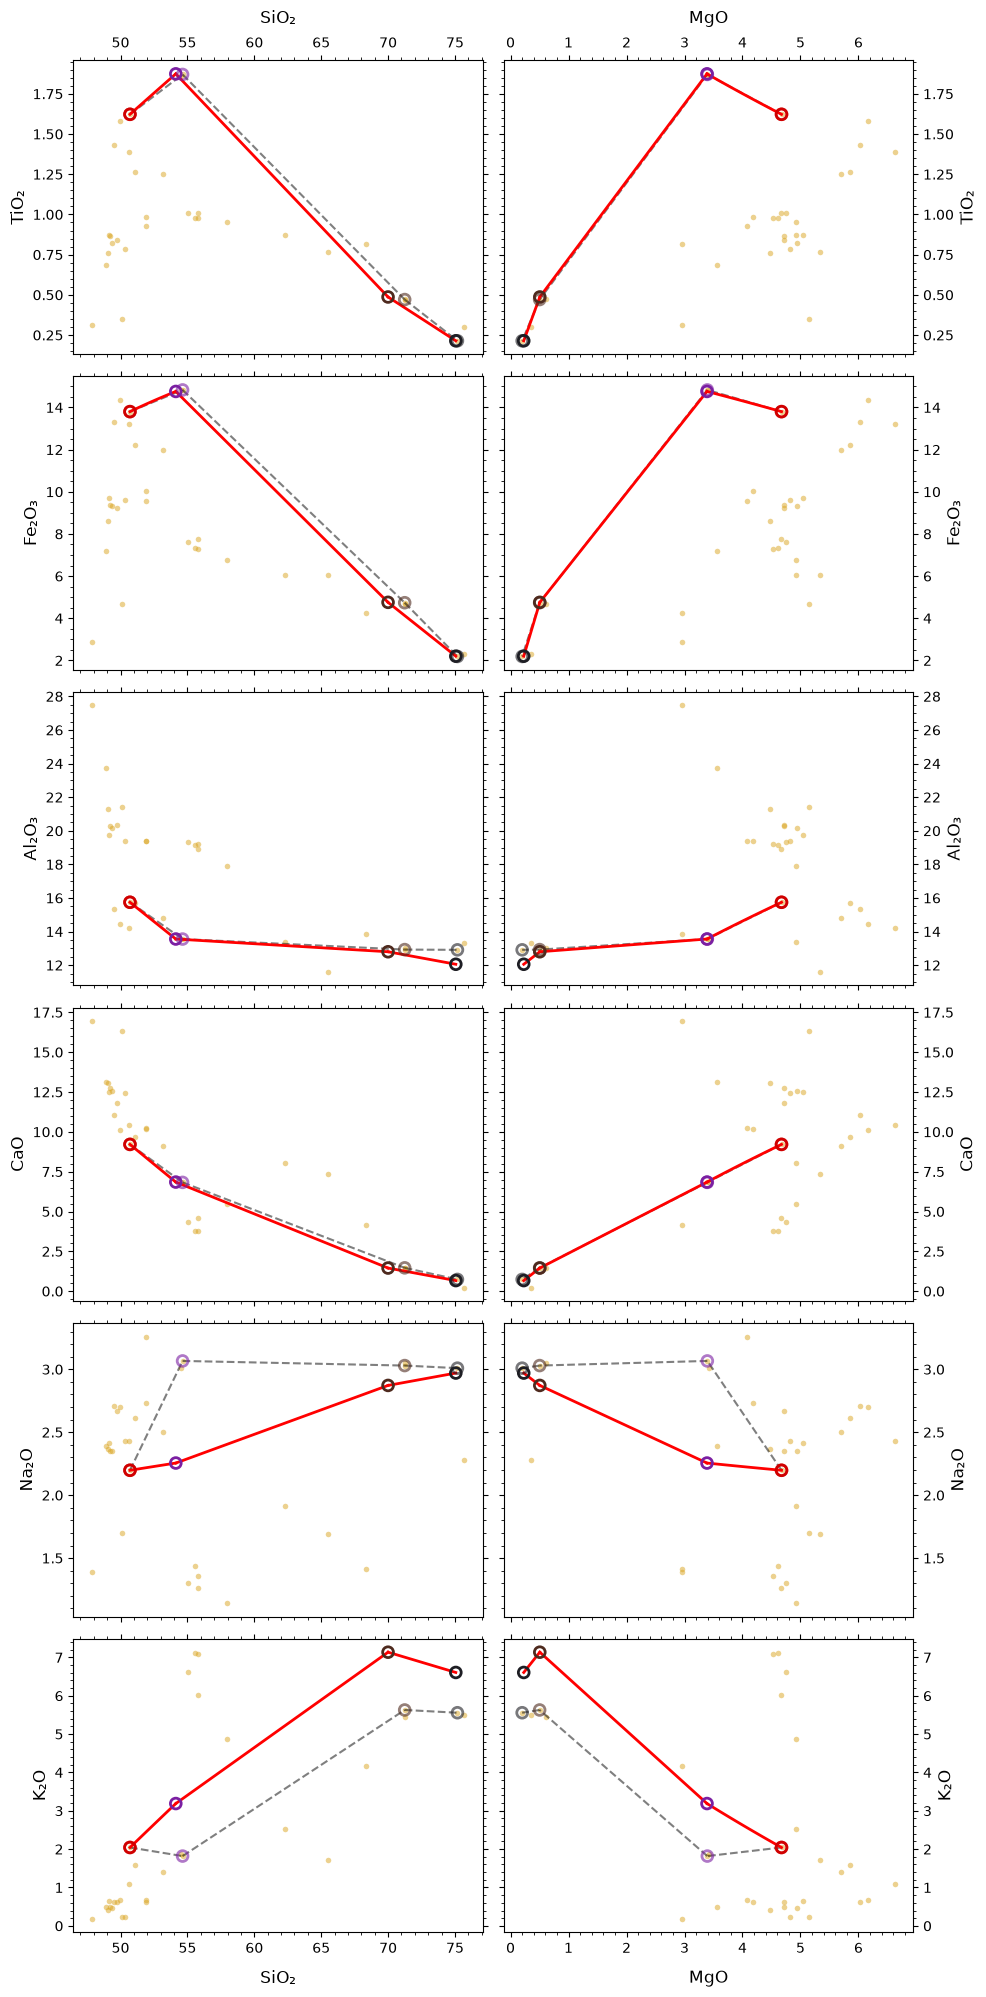

In [6]:
# Plot bivariate plots for the major oxides and save to a file
from hades.visuals import bivar
bivar(
    model, 
    y_order=['TiO2', 'Fe2O3', 'Al2O3', 'CaO', 'Na2O', 'K2O'], 
    filename='./outputs/bivariate_plots.png',
)

**Exporting Results**

We can export the results as a PDF and an Excel file, and also save the model configuration for future use. See details at the end of the notebook.

In [7]:
model.savePDF('./outputs/results.pdf')
model.saveData('./outputs/data_output.xlsx')

# First, we save the .hades config file
model.save_config('./carlingford.hades')

PDF compilation completed. Output saved to ./outputs/results.pdf
Excel file saved successfully: ./outputs/data_output.xlsx
Successfully saved configuration to ./carlingford.hades


**Assimilation Model**

We see that the computed LLOD does not match that as chosen with our initial composition in the intermedia and evolved stages.

Meade et al. (2013) show major element AFC trends from the Carlingford mafic rocks towards the intermediate rocks in the cone sheet. We can replicate this contamination in Hades using the 'assimilant' function.

For the AFC case study we load the same input file but adjust the samples used for the initial LLOD. We use the same contributing minerals but keep Kd values as their defaults unlike in the non-AFC example above.

In [8]:
# Create a new model and load the data and select samples
model = Obol.newModel()
model.load_data_suite('carlingford.xlsx')
model.select_initial_composition([None, None, 'GM1', 'CB3', 'C-CS-SR', None])

Primary       : n/a
Primitive     : n/a
Basic         : 'GM1'
Intermediate  : 'CB3'
Evolved       : 'C-CS-SR'
End           : n/a
3/6 phases have been set with user-provided initial compositions.


In [9]:
# Define which minerals contribute to the assemblage and in which phases - same as non-AFC case
model.set_mineral_usage(
    __=False,
    basic__olivine=True,
    basic__plagioclase=True,
    basic__cpx=True,
    basic__magnetite=True,
    basic__ilmenite=True,
    intermediate__olivine=False,
    intermediate__plagioclase=True,
    intermediate__opx=True,
    intermediate__cpx=True,
    intermediate__magnetite=True,
    intermediate__ilmenite=True,
    evolved__kfeldspar=True,
    evolved__cpx=True,
    evolved__magnetite=True,
    evolved__ilmenite=True,
)

We now load the assimilant composition file and specify the 50% of the assimilant to be introduced during both the basic and intermediate stages.

In [10]:
model.set_assimilant(filepath='Carlingford_Assimilant.xlsx', percentages=[0, 0, 50, 50, 0])

Loaded assimilant data from 'Carlingford_Assimilant.xlsx'


In [11]:
# Run stages 3 and 4 (basic and intermediate) of the model
model.run(3)
model.run(4)

> Optimisation completed with cost = 1.03 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'
> Optimisation completed with cost = 4.97 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'


In [12]:
# Show results
model.summary()

                        B-I        I-E     |     Total   
----------------------------------------------------------------
            Type  |    Majors     Majors   |            
            Cost  |      1.03       4.97   |            
----------------------------------------------------------------
               F  |        37         60   |       100    %
         Olivine  |    12.334              |     6.101    wt.%
          Spinel  |                        |              wt.%
   Clinopyroxene  |    37.564     33.606   |    35.564    wt.%
   Orthopyroxene  |               10.077   |     5.092    wt.%
     Plagioclase  |    39.125     42.686   |    40.925    wt.%
       Amphibole  |                        |              wt.%
      K-feldspar  |                        |              wt.%
         Biotite  |                        |              wt.%
          Quartz  |                        |              wt.%
       Magnetite  |     9.623     12.553   |    11.104    wt.%
        

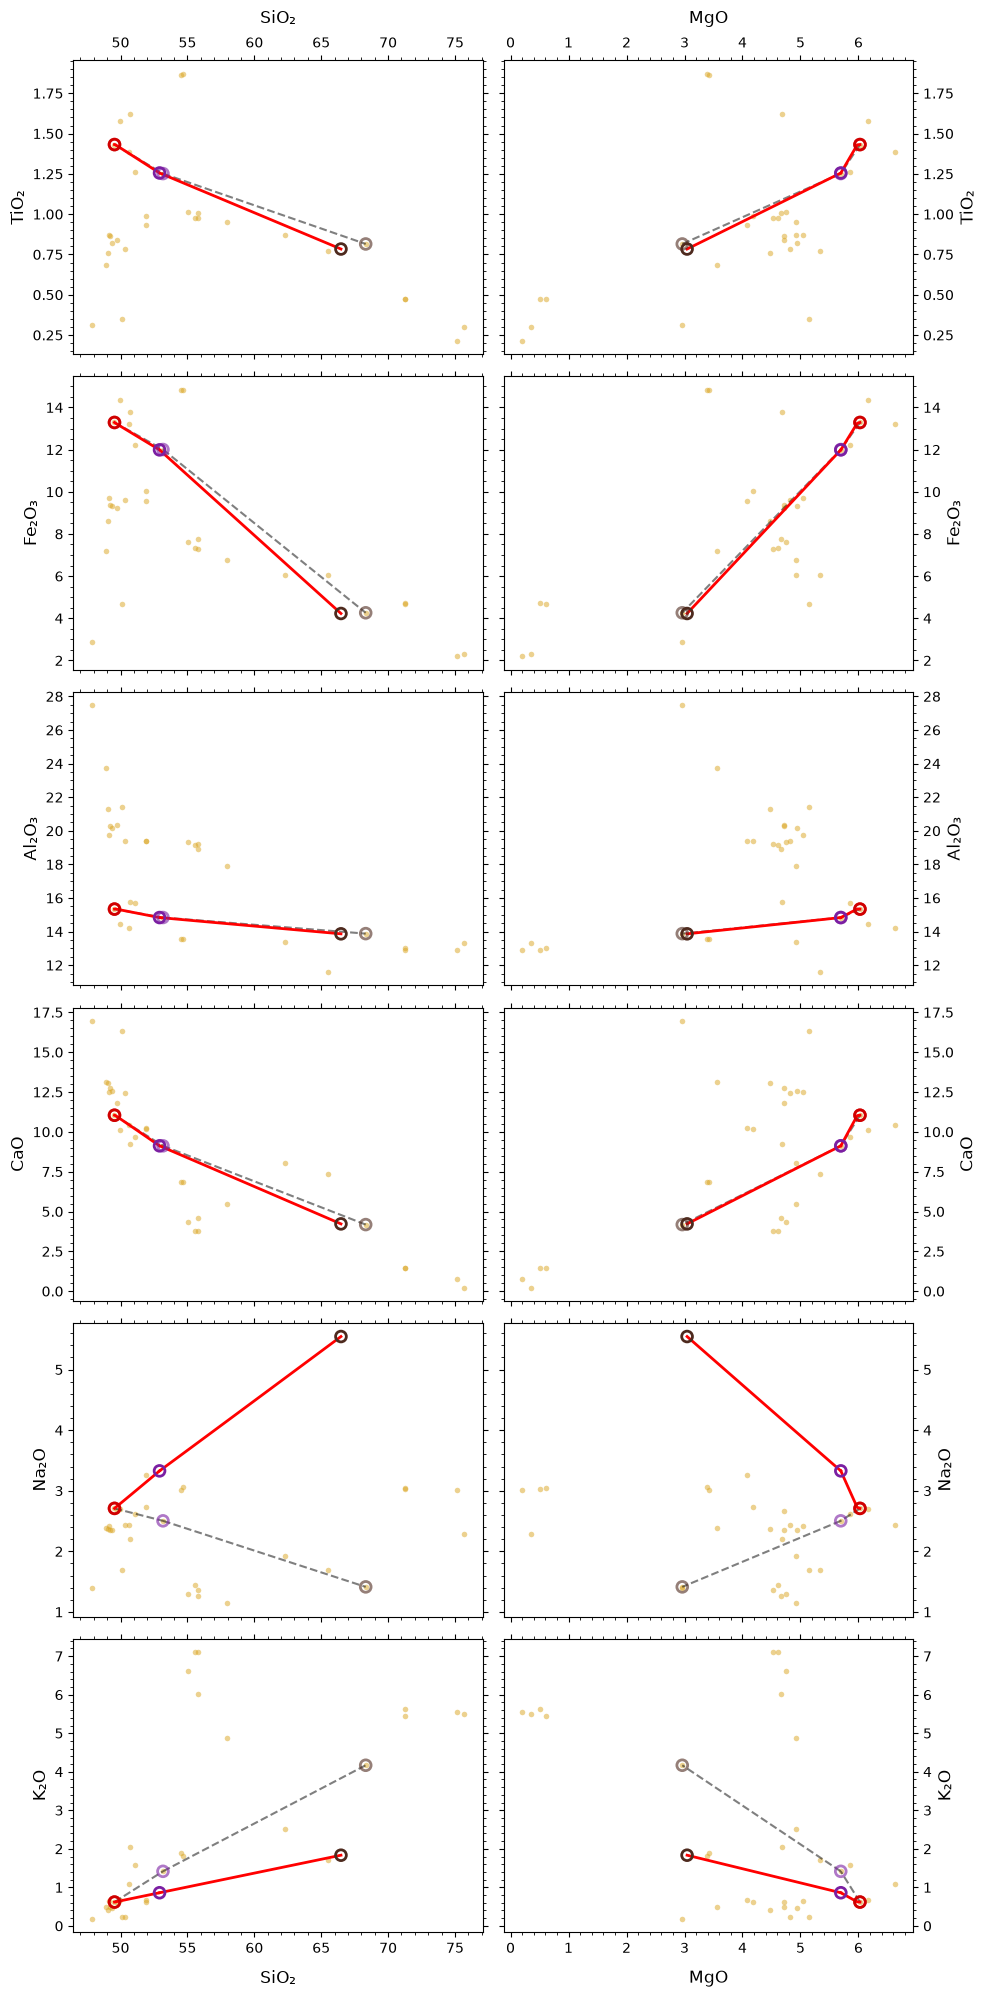

In [13]:
# Plot bivariate plots for the major oxides and save to a file
from hades.visuals import bivar
bivar(
    model, 
    y_order=['TiO2', 'Fe2O3', 'Al2O3', 'CaO', 'Na2O', 'K2O'], 
    filename='./outputs/afc_bivariate_plots.png',
)

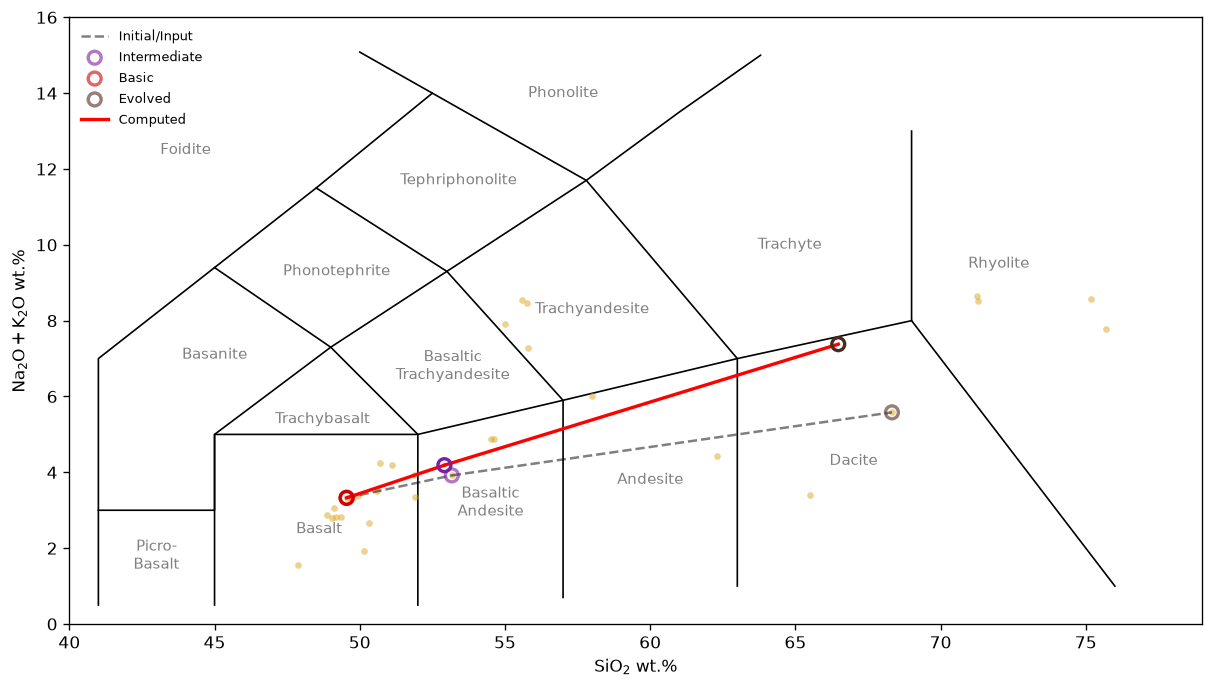

In [14]:
# Plot the TAS diagram and save to a file
from hades.visuals import tas
tas(
    model, 
    filename='./outputs/afc_tas_diagram.png'
)

**Export Results**

We now export the results for the AFC model. The results for the non-afc modelling earlier could also be exported after being run, if desired.

In [15]:
model.savePDF('./outputs/afc_results.pdf')
model.saveData('./outputs/afc_data_output.xlsx')

PDF compilation completed. Output saved to ./outputs/afc_results.pdf
Excel file saved successfully: ./outputs/afc_data_output.xlsx


----

**Useful Commands**

Configuration Files

Having imported data and configured our desired parameters, we can save the configuration to a ``.hades`` file. This allows us to easily reload the model configuration in the future (either in Python or the Hades Windows application) without having to re-import data or reconfigure parameters.

See the documentation for more information on [saving and loading model configurations](https://hades-obol.readthedocs.io/en/latest/user_manual/config_files.html).

In [16]:
model.save_config('./afc_carlingford.hades')

Successfully saved configuration to ./afc_carlingford.hades


To use a ``.hades`` configuration file to initialise a model, simply create a fresh model and call the ``load_config`` method with the path to the configuration file. This will automatically import the data and set all parameters as specified in the configuration file, overwriting any arguments passed to the ``newModel`` method.

In [17]:
model = Obol.newModel()
model.load_config('./afc_carlingford.hades')

 To adjust the population size and maximum number of generations, you can use the following code before running the model

In [18]:
# model.optimising.max_iter = 500 # default
# model.optimising.pop_size = 50  # default